## Stage 15 — Signal Audit: what is the 0.9998 really made of?

A near-perfect PR-AUC should make you suspicious, not proud. This notebook asks three questions:

1. **How far does one simple rule get?** PaySim's fraud script empties the sender's account, so test `amount == oldbalanceOrg`.
2. **What if the model only uses data available *at decision time*?** `newbalanceOrig`, `newbalanceDest` and everything derived from them (`errorBalance*`, `flag_orig_zero_after`, `flag_dest_zero_both`) are known only *after* the transaction posts. A real-time fraud system scoring a payment before it clears wouldn't have them.
3. **What is left without the sender's balance?** This shows how much of the signal is the simulator's "drain the account" script.

Run after Stage 6 (it rebuilds the same time split from `data/paysim_raw.parquet`). Stage 13 adds the results to the app bundle if `models/ablation.joblib` exists.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import xgboost as xgb
from sklearn.metrics import average_precision_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

RANDOM_STATE = 42
PARQUET_RAW  = os.path.join("data", "paysim_raw.parquet")
MODEL_META   = os.path.join("models", "model_meta.joblib")
ABLATION     = os.path.join("models", "ablation.joblib")
FIGURES_DIR  = os.path.join("reports", "figures")
TRAIN_FRAC, VAL_FRAC = 0.80, 0.10        # must match Stages 6 and 8
os.makedirs(FIGURES_DIR, exist_ok=True)

### 1. Rebuild the data — with destination history added

`dest_prior_txns` / `dest_prior_amount` count what the receiving account did in **earlier hours only** (all transaction types). That's information a real system has at decision time.

In [2]:
raw = pd.read_parquet(PARQUET_RAW)

# Destination history: per (account, hour), then cumulative sum MINUS the
# current hour → only strictly earlier hours are counted (no look-ahead).
hist = (raw.groupby(["nameDest", "step"], observed=True)
           .agg(n=("amount", "size"), amt=("amount", "sum"))
           .reset_index()
           .sort_values(["nameDest", "step"]))
hist["dest_prior_txns"]   = hist.groupby("nameDest")["n"].cumsum()   - hist["n"]
hist["dest_prior_amount"] = hist.groupby("nameDest")["amt"].cumsum() - hist["amt"]

df = raw[raw["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
df = df.merge(hist[["nameDest", "step", "dest_prior_txns", "dest_prior_amount"]],
              on=["nameDest", "step"], how="left")
del raw, hist

# Features — same definitions as Stage 5, plus decision-time extras
f64 = lambda c: df[c].astype("float64")
df["type_TRANSFER"]         = (df["type"] == "TRANSFER").astype("int8")
df["errorBalanceOrig"]      = f64("newbalanceOrig") + f64("amount") - f64("oldbalanceOrg")
df["errorBalanceDest"]      = f64("oldbalanceDest") + f64("amount") - f64("newbalanceDest")
df["flag_orig_zero_after"]  = (df["newbalanceOrig"] == 0).astype("int8")
df["flag_dest_zero_before"] = (df["oldbalanceDest"] == 0).astype("int8")
df["flag_dest_zero_both"]   = ((df["oldbalanceDest"] == 0) & (df["newbalanceDest"] == 0)).astype("int8")
df["hour_of_day"]           = (df["step"] % 24).astype("int8")
df["drain_ratio"]           = np.where(df["oldbalanceOrg"] > 0, f64("amount") / f64("oldbalanceOrg"), -1.0)
df["flag_exact_drain"]      = np.isclose(f64("amount"), f64("oldbalanceOrg"), atol=0.5).astype("int8")

# Same time-aware split as Stage 6, same validation slice as Stage 8
SPLIT_STEP = int(df["step"].quantile(TRAIN_FRAC))
train = df[df["step"] <= SPLIT_STEP]
test  = df[df["step"] >  SPLIT_STEP]
cut   = int(len(train) * (1 - VAL_FRAC))
tr, val = train.iloc[:cut], train.iloc[cut:]
y_test  = test["isFraud"].astype(int)

print(f"Split step {SPLIT_STEP}:  train {len(train):,}  |  test {len(test):,} ({y_test.sum():,} frauds)")
print(f"PR-AUC baseline (test fraud rate): {y_test.mean():.4f}")

Split step 354:  train 2,217,905  |  test 552,504 (4,258 frauds)
PR-AUC baseline (test fraud rate): 0.0077


### 2. One rule: flag a transfer that moves the sender's *entire* balance

In [3]:
rule = test["flag_exact_drain"].astype(bool)
tp = int((rule & (y_test == 1)).sum())
RULE_RECALL    = tp / y_test.sum()
RULE_PRECISION = tp / rule.sum()
print(f"Rule: amount == oldbalanceOrg")
print(f"  Flags      : {rule.sum():,}")
print(f"  Recall     : {RULE_RECALL:.4f}   ({tp:,} of {y_test.sum():,} frauds)")
print(f"  Precision  : {RULE_PRECISION:.4f}")
print()
print("One if-statement catches almost all PaySim fraud. That is the simulator's")
print("fraud script, not something a model 'discovered'.")

Rule: amount == oldbalanceOrg
  Flags      : 4,154
  Recall     : 0.9753   (4,153 of 4,258 frauds)
  Precision  : 0.9998

One if-statement catches almost all PaySim fraud. That is the simulator's
fraud script, not something a model 'discovered'.


### 3. Same model settings, three feature sets

In [4]:
FEATURE_SETS = {
    "A. Full model (11 features, incl. post-transaction balances)": [
        "amount", "type_TRANSFER", "oldbalanceOrg", "newbalanceOrig",
        "oldbalanceDest", "newbalanceDest", "errorBalanceOrig", "errorBalanceDest",
        "flag_orig_zero_after", "flag_dest_zero_before", "flag_dest_zero_both"],
    "B. Decision-time only": [
        "amount", "type_TRANSFER", "oldbalanceOrg", "oldbalanceDest",
        "flag_dest_zero_before", "drain_ratio", "hour_of_day",
        "dest_prior_txns", "dest_prior_amount"],
    "C. Decision-time, without sender balance": [
        "amount", "type_TRANSFER", "oldbalanceDest", "flag_dest_zero_before",
        "hour_of_day", "dest_prior_txns", "dest_prior_amount"],
}

spw = round((tr["isFraud"] == 0).sum() / tr["isFraud"].sum(), 2)
results = []
for name, cols in FEATURE_SETS.items():
    t0 = time.time()
    model = xgb.XGBClassifier(
        n_estimators=1000, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
        eval_metric=["aucpr", "logloss"],   # early stopping watches logloss (see Stage 8)
        early_stopping_rounds=50, tree_method="hist",
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=0,
    )
    model.fit(tr[cols], tr["isFraud"], eval_set=[(val[cols], val["isFraud"])], verbose=False)
    pr_auc = average_precision_score(y_test, model.predict_proba(test[cols])[:, 1])
    results.append({
        "feature_set": name,
        "n_features": len(cols),
        "uses_post_transaction_data": name.startswith("A."),
        "test_pr_auc": round(float(pr_auc), 4),
        "trees": int(model.best_iteration + 1),
    })
    print(f"{name:<62} PR-AUC = {pr_auc:.4f}   ({model.best_iteration + 1} trees, {time.time()-t0:.0f}s)")

results_df = pd.DataFrame(results)
results_df

A. Full model (11 features, incl. post-transaction balances)   PR-AUC = 1.0000   (560 trees, 63s)


B. Decision-time only                                          PR-AUC = 0.9871   (993 trees, 99s)


C. Decision-time, without sender balance                       PR-AUC = 0.5908   (1000 trees, 93s)


,feature_set,n_features,uses_post_transaction_data,test_pr_auc,trees
0,"A. Full model (11 features, incl. post-transac...",11,True,1.0000,560
1,B. Decision-time only,9,False,0.9871,993
2,"C. Decision-time, without sender balance",7,False,0.5908,1000


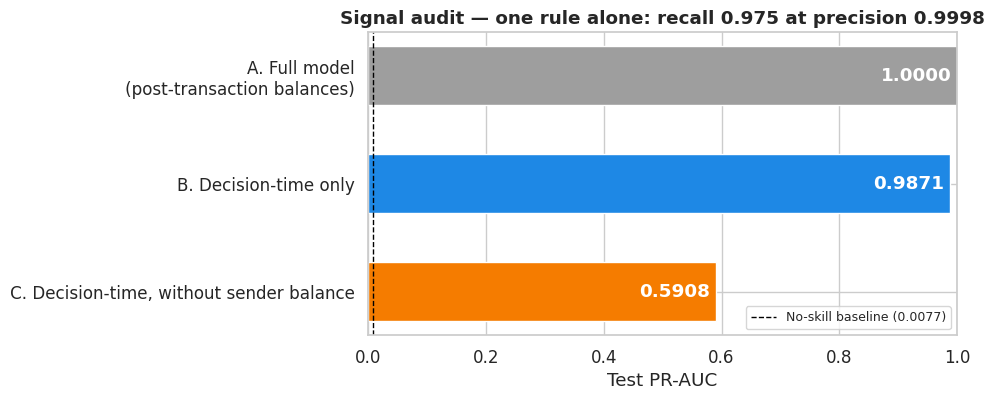

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
labels = [r["feature_set"] for r in results] + ["Rule: amount == sender balance"]
labels = [l.replace(" (11 features, incl. post-transaction balances)", "\n(post-transaction balances)") for l in labels]
values = [r["test_pr_auc"] for r in results]
colors = ["#9E9E9E", "#1E88E5", "#F57C00"]
bars = ax.barh(labels[:3][::-1], values[::-1], color=colors[::-1], height=0.55)
for b, v in zip(bars, values[::-1]):
    ax.text(v - 0.01, b.get_y() + b.get_height() / 2, f"{v:.4f}", va="center", ha="right",
            color="white", fontweight="bold")
ax.axvline(y_test.mean(), color="black", linestyle="--", linewidth=1,
           label=f"No-skill baseline ({y_test.mean():.4f})")
ax.set_xlim(0, 1.0)
ax.set_xlabel("Test PR-AUC")
ax.set_title(f"Signal audit — one rule alone: recall {RULE_RECALL:.3f} at precision {RULE_PRECISION:.4f}",
             fontweight="bold")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "ablation_signal_audit.png"), dpi=150, bbox_inches="tight")
plt.show()

In [6]:
joblib.dump({
    "results": results,
    "rule": {"name": "amount == oldbalanceOrg",
             "recall": round(float(RULE_RECALL), 4),
             "precision": round(float(RULE_PRECISION), 4)},
    "test_rows": int(len(test)),
    "test_frauds": int(y_test.sum()),
    "baseline": round(float(y_test.mean()), 4),
}, ABLATION)
print(f"Saved → {ABLATION}  (Stage 13 adds it to the app bundle)")

Saved → models/ablation.joblib  (Stage 13 adds it to the app bundle)


### Takeaways

- The full model's ~0.9998 leans on fields that exist only **after** a transaction posts.
- Restricted to decision-time data, the model still scores very high — because PaySim fraud **drains the sender's exact balance**, and one rule alone catches almost all of it.
- Remove the sender balance and PR-AUC drops sharply. That gap is the honest measure of how scripted the simulator is.
- On real data, expect far lower numbers, delayed labels, and fraud that adapts (see the Stage 12 drift replay).